# Novelty assessment: four extra checks on the frequency detector

The main experiment (`demo.ipynb`) shows that frequency features beat pixel features on held-out clips.
Four questions it leaves open:

1. Is the **fine detail** really what the models use? (resize vs native crop)
2. Do the **temporal features** use real frame-to-frame behaviour? (frame order)
3. Does it still work on **new content**? (prompt-disjoint test)
4. Would a **strong image network** make it unnecessary? (ResNet-18 and late fusion)

Each section reads a result file in `results_crop/`, written by the script named under the heading. All numbers are AUROC on held-out clips (1.0 = perfect, 0.5 = guessing).

In [1]:
import os, sys
sys.path.insert(0, os.getcwd())
import pandas as pd, matplotlib.pyplot as plt
from src.config import RESULTS
%matplotlib inline

## 1. Resize vs native crop

*Script: `src/eval/resize_ablation.py`; file: `resize_ablation_cv.csv`.*

**Idea:** shrinking a frame is a low-pass filter, so it should remove the fine detail that the frequency features measure.
**What we did:** the same clips, the same splits and the same models, with every frame either cut at native resolution (crop) or shrunk to 256 px first (resize). 5-fold grouped cross-validation.

features  pixel  frequency  fusion
model                             
lr        0.007     -0.094  -0.051
mlp       0.031     -0.084  -0.040 
(change in AUROC when resized; negative = worse)


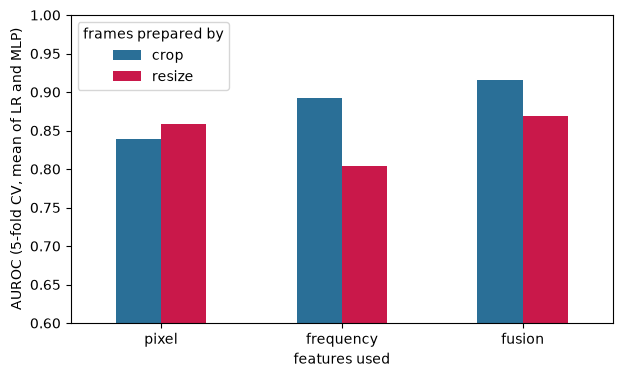

In [2]:
r = pd.read_csv(RESULTS / "resize_ablation_cv.csv")
r["features"] = r.features.replace({"all": "frequency"})
r = r[r.features.isin(["pixel", "frequency", "fusion"]) & (r.model != "lgbm")]

print(r.pivot(index="model", columns="features", values="resize_minus_crop")[["pixel", "frequency", "fusion"]].to_string(),
      "\n(change in AUROC when resized; negative = worse)")
ax = r.groupby("features")[["crop", "resize"]].mean().loc[["pixel", "frequency", "fusion"]].plot.bar(
    rot=0, ylim=(0.6, 1), color=["#2a6f97", "#c9184a"], figsize=(7, 4))
ax.set(xlabel="features used", ylabel="AUROC (5-fold CV, mean of LR and MLP)"); ax.legend(title="frames prepared by");

**Finding:** resizing costs the frequency models 0.08 to 0.09 AUROC. Pixel models do not drop. So the frequency features do depend on fine detail that resizing removes.

## 2. Frame order

*Script: `src/eval/temporal_order.py`; file: `temporal_order.csv`.*

**Idea:** if the temporal features measure real frame-to-frame behaviour, scrambling the order should hurt them, and it should not affect features of single frames.
**What we did:** reversed, then shuffled, the 14 frames of every held-out clip, recomputed the features, and re-scored the same trained models (seen generators).

       model  variant  auroc_original  auroc_variant  change
     mlp_all reversed           0.960          0.960   0.000
     mlp_all shuffled           0.960          0.943  -0.017
 mlp_spatial reversed           0.944          0.944   0.000
 mlp_spatial shuffled           0.944          0.944   0.000
mlp_temporal reversed           0.933          0.933   0.000
mlp_temporal shuffled           0.933          0.795  -0.138


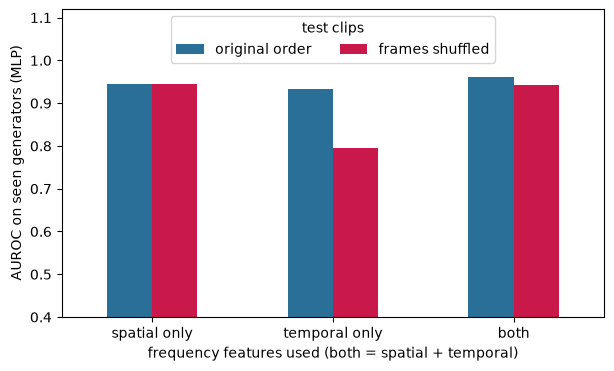

In [3]:
o = pd.read_csv(RESULTS / "temporal_order.csv")
o = o[(o.set == "seen") & o.model.str.startswith("mlp")]
print(o[["model", "variant", "auroc_original", "auroc_variant", "change"]].to_string(index=False))

d = o[o.variant == "shuffled"].set_index("model").loc[["mlp_spatial", "mlp_temporal", "mlp_all"]]
d.index = ["spatial only", "temporal only", "both"]
ax = d[["auroc_original", "auroc_variant"]].rename(columns={"auroc_original": "original order", "auroc_variant": "frames shuffled"}).plot.bar(
    rot=0, ylim=(0.4, 1.12), color=["#2a6f97", "#c9184a"], figsize=(7, 4))
ax.set(xlabel="frequency features used (both = spatial + temporal)", ylabel="AUROC on seen generators (MLP)")
ax.legend(title="test clips", loc="upper center", ncol=2);

**Finding:** reversal changes nothing (the drift statistics are symmetric in time). Shuffling costs the temporal-only MLP 0.14, the spatial-only MLP nothing, and the combined MLP 0.02. The temporal features do use real frame-to-frame behaviour.

## 3. New content: prompt-disjoint test

*Scripts: `src/generate/modelscope.py --fresh`, then `src/eval/fresh_prompts.py`; files: `fresh_prompts.csv`, `fresh_prompts_diffs.csv`.*

**Idea:** the unseen-generator test sets reuse the 60 prompts the training clips were made from, so their content matches the training fakes.
**What we did:** regenerated ModelScope from 36 **new** prompts (72 clips) and scored them with the already-trained models, with no retraining, against the same 65 real test clips.

               auroc_old_prompts  auroc_new_prompts  change
model                                                      
lr_pixel                   0.657              0.584  -0.073
mlp_pixel                  0.611              0.462  -0.148
lr_frequency               0.753              0.688  -0.065
mlp_frequency              0.792              0.721  -0.071
lr_fusion                  0.770              0.721  -0.050
mlp_fusion                 0.738              0.643  -0.095
resnet18                   0.905              0.893  -0.012 



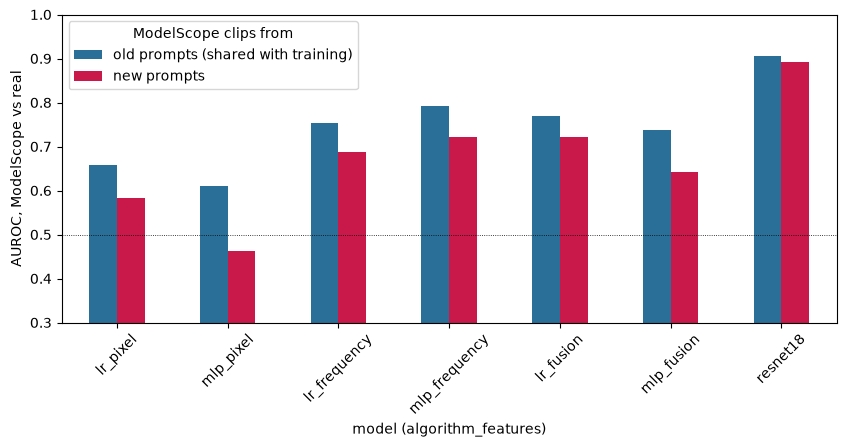

In [4]:
f = pd.read_csv(RESULTS / "fresh_prompts.csv").set_index("model")
f.index = f.index.str.replace("_all", "_frequency")
f = f[~f.index.str.startswith("lgbm")]
print(f[["auroc_old_prompts", "auroc_new_prompts", "change"]].to_string(), "\n")
ax = f[["auroc_old_prompts", "auroc_new_prompts"]].rename(columns={"auroc_old_prompts": "old prompts (shared with training)",
                                                                  "auroc_new_prompts": "new prompts"}).plot.bar(
    rot=45, ylim=(0.3, 1), color=["#2a6f97", "#c9184a"], figsize=(10, 4))
ax.axhline(0.5, color="k", lw=0.6, ls=":")
ax.set(xlabel="model (algorithm_features)", ylabel="AUROC, ModelScope vs real"); ax.legend(title="ModelScope clips from");

In [5]:
d = pd.read_csv(RESULTS / "fresh_prompts_diffs.csv")
d = d[(d.set == "new prompts") & (d.a == "mlp_all") & (d.b == "mlp_pixel")]
print("new prompts, frequency MLP minus pixel MLP:", d[["auroc_a", "auroc_b", "a_minus_b", "ci_low", "ci_high"]].round(3).to_string(index=False))

new prompts, frequency MLP minus pixel MLP:  auroc_a  auroc_b  a_minus_b  ci_low  ci_high
   0.721    0.462      0.259   0.173    0.341


**Finding:** every pixel and frequency model loses 0.05 to 0.15 on new prompts, so part of the earlier unseen-generator score came from content overlap. ResNet-18 barely moves (0.905 to 0.893). Frequency still beats pixel (MLP +0.259, 95% interval +0.173 to +0.341). One unseen generator and 72 clips only.

## 4. Strong image network: ResNet-18 and late fusion

*Script: `src/eval/late_fusion.py`; file: `late_fusion.csv`.*

**Question:** is the frequency detector needed once a fine-tuned ResNet-18 exists, and do the two help each other?
**What we did:** combined the ResNet-18 score and the frequency-model score with a 2-weight logistic stacker fitted on the seen **validation** clips only, then scored the held-out sets.

            resnet18  frequency_mlp  fused  fused_minus_resnet  fused_minus_frequency
set                                                                                  
seen           0.967          0.960  0.971               0.004                  0.012
modelscope     0.905          0.787  0.850              -0.055                  0.063
wan            0.933          0.655  0.738              -0.195                  0.083 



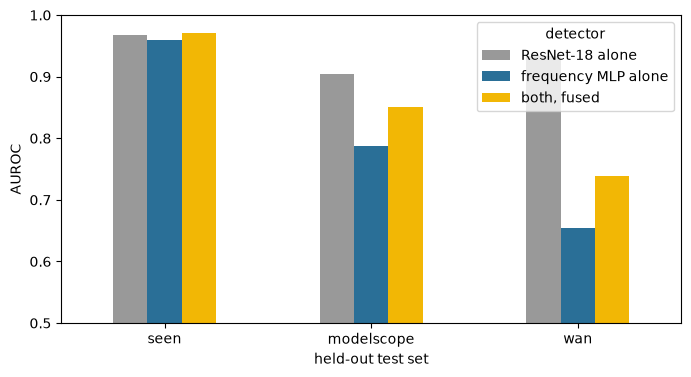

In [6]:
lf = pd.read_csv(RESULTS / "late_fusion.csv").set_index("set").loc[["seen", "modelscope", "wan"]]
print(lf[["resnet18", "frequency_mlp", "fused", "fused_minus_resnet", "fused_minus_frequency"]].to_string(), "\n")
ax = lf[["resnet18", "frequency_mlp", "fused"]].rename(columns={"resnet18": "ResNet-18 alone", "frequency_mlp": "frequency MLP alone",
                                                                  "fused": "both, fused"}).plot.bar(
    rot=0, ylim=(0.5, 1), color=["#999999", "#2a6f97", "#f2b705"], figsize=(8, 4))
ax.set(xlabel="held-out test set", ylabel="AUROC"); ax.legend(title="detector");

**Finding (partly negative):**
- Fusion helps the frequency model on unseen generators (+0.06 ModelScope, +0.08 Wan2.1).
- It does **not** help ResNet-18 (seen +0.004, ModelScope -0.055, Wan2.1 -0.195).
- ResNet-18 alone scores higher than our frequency model on all three sets, so the frequency detector is not a replacement for it; its value is that it is small, interpretable and cheap.
- ResNet-18 is a single trained checkpoint (one seed).

## Summary

| # | Question | Finding |
|---|---|---|
| 1 | Does the detector use fine detail? | Yes: resizing costs frequency models 0.08 to 0.09; pixel models do not drop |
| 2 | Do temporal features use real frame order? | Yes: shuffling costs the temporal-only MLP 0.14; spatial-only unchanged |
| 3 | Does it hold on new content? | Partly: every model loses 0.05 to 0.15; frequency still beats pixel (+0.26 MLP) |
| 4 | Does a strong image network replace it? | No gain from fusion for ResNet-18, which scores higher alone; fusion helps our model by 0.06 to 0.08 |